# Deepfake Detection: Data Loading

**Dataset:** Tiny-GenImage (Hugging Face), real photographs and AI-generated images from eight generators.

In [1]:
from datasets import load_dataset

# Streamed rather than downloaded: the full dataset is ~8 GB.
ds = load_dataset("TheKernel01/Tiny-GenImage", split="train", streaming=True)

print(ds.features)

~/Documents/FA26-COMP-671-Muthineni/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['real', 'fake']), 'generator': ClassLabel(names=['Real', 'ADM', 'BigGAN', 'GLIDE', 'Midjourney', 'SD14', 'SD15', 'VQDM', 'Wukong'])}


## 2. Exploring the data

In [2]:
import pandas as pd

# Metadata only (no images) for the first 2,000 rows.
meta = ds.select_columns(["label", "generator"])
df = pd.DataFrame(list(meta.take(2000)))

df["label_name"] = df["label"].map(ds.features["label"].int2str)
df["generator_name"] = df["generator"].map(ds.features["generator"].int2str)

df.shape

(2000, 4)

In [3]:
df.head()

,label,generator,label_name,generator_name
0,0,0,real,Real
1,1,1,fake,ADM
2,0,0,real,Real
3,1,2,fake,BigGAN
4,0,0,real,Real


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   label           2000 non-null   int64
 1   generator       2000 non-null   int64
 2   label_name      2000 non-null   str  
 3   generator_name  2000 non-null   str  
dtypes: int64(2), str(2)
memory usage: 79.6 KB


In [5]:
print(df["label_name"].value_counts())
print(df["generator_name"].value_counts())

label_name
real    1000
fake    1000
Name: count, dtype: int64
generator_name
Real          1000
ADM            143
BigGAN         143
GLIDE          143
Midjourney     143
SD15           143
VQDM           143
Wukong         142
Name: count, dtype: int64


## 3. Building the image subset

In [6]:
import numpy as np

want = {"Real": 525, "SD15": 375, "Midjourney": 150}
got = {"Real": [], "SD15": [], "Midjourney": []}

names = ds.features["generator"].names

for row in ds:
    gen = names[row["generator"]]
    if gen not in got or len(got[gen]) >= want[gen]:
        continue
    img = row["image"].convert("RGB").resize((32, 32))
    got[gen].append(np.array(img))
    if all(len(got[k]) >= want[k] for k in want):
        break

for k in got:
    print(k, len(got[k]))

Real 525
SD15 375
Midjourney 150


Matplotlib is building the font cache; this may take a moment.


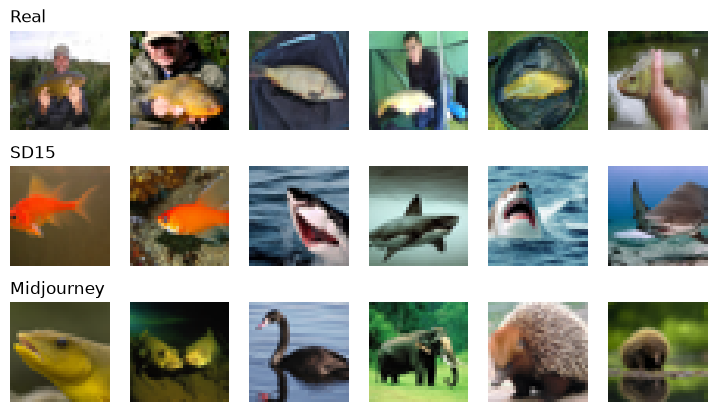

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 6, figsize=(9, 5))

for row_num, name in enumerate(["Real", "SD15", "Midjourney"]):
    for col_num in range(6):
        axes[row_num, col_num].imshow(got[name][col_num])
        axes[row_num, col_num].axis("off")
    axes[row_num, 0].set_title(name, loc="left")

plt.show()

## 4. Data integrity checks

In [8]:
all_imgs = got["Real"] + got["SD15"] + got["Midjourney"]

print("Total images:", len(all_imgs))
print("Shape of one image:", all_imgs[0].shape)
print("Smallest pixel value:", min(img.min() for img in all_imgs))
print("Largest pixel value:", max(img.max() for img in all_imgs))

# Duplicate check: identical images have identical bytes
unique = set(img.tobytes() for img in all_imgs)
print("Unique images:", len(unique))

for img in all_imgs:
    assert img.shape == (32, 32, 3)
print("All shape checks passed")

Total images: 1050
Shape of one image: (32, 32, 3)
Smallest pixel value: 0
Largest pixel value: 255
Unique images: 1050
All shape checks passed
